<a href="https://colab.research.google.com/github/CactusDataMafia/dl_sem_7/blob/master/Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛАБОРАТОРНАЯ РАБОТА №1
## Полносвязные сети, обратное распространение ошибки и геометрия признакового пространства

### Цель работы
Понять, как полносвязные сети формируют разделяющие поверхности и внутренние представления данных. Научиться анализировать не только accuracy, но и геометрию пространства признаков, устойчивость модели и поведение современных архитектур.

#### Часть 1. Синтетический датасет «круг vs кольцо»

Шаги реализации:
1. Сгенерировать 2D-датасет из 1500 точек:
   - Класс 0: равномерное распределение внутри круга радиуса 0.8
   - Класс 1: равномерное распределение в кольце (радиусы от 1 до 2)
   - Баланс классов 1:1
2. Построить scatter-plot исходного распределения
3. Разделить на train/validation/test (70/15/15) со стратификацией
4. Обучить три модели с фиксированным random seed:
   - Модель A: ≤2 скрытых слоёв, ≤2 нейронов на слой, активация ReLU
   - Модель B: 2–3 слоя, >2 нейронов (например, 16), активация ReLU
   - Модель C: как A, но с активацией GELU
5. Для каждой модели построить:
   - Кривые обучения (train loss, val accuracy)
   - Границу решения на плоскости (через сетку 200×200)
   - Итоговую таблицу: число параметров, test accuracy, время обучения

#### Часть 2. Внутреннее признаковое пространство

Шаги реализации:
1. Извлечь эмбеддинги из предпоследнего слоя каждой обученной модели для тестовой выборки
2. Если размерность > 2, применить t-SNE (perplexity=20) или PCA
3. Построить 2D-визуализацию, где разным классам соответствуют разные цвета
4. Сравнить:
   - Исходное пространство координат (x₁, x₂)
   - Пространство признаков после обучения
5. Сделать вывод о том, как сеть «распутывает» линейно-неразделимые классы

#### Часть 3. Шум, выбросы и устойчивость

Шаги реализации:
1. Добавить гауссов шум к тестовым данным с уровнями σ ∈ {0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0}
2. Для каждой модели измерить accuracy на зашумлённых данных
3. Построить график: σ → accuracy для всех трёх моделей
4. Мини-исследование: определить, что сильнее влияет на результат:
   - шум входа,
   - выбросы (случайные точки далеко от классов),
   - уменьшение числа нейронов

#### Часть 4. Kolmogorov-Arnold Networks (KAN)

Шаги реализации:
1. Сгенерировать синтетическую многомерную функцию, например:
   `f(x,y) = sin(πx)·cos(πy) + x² − y²`
2. Обучить классический MLP (3 слоя, 16 нейронов)
3. Обучить упрощённый KAN (реализация с B-сплайнами или их аппроксимацией)
4. Сравнить:
   - Число параметров
   - Скорость сходимости (MSE по эпохам)
   - Качество аппроксимации на тесте
5. Сделать вывод об эффективности KAN на гладких функциях

In [16]:
# === ПРОВЕРКА СРЕДЫ ВЫПОЛНЕНИЯ ===
# В Google Colab: Runtime -> Change runtime type -> GPU (ускорит обучение).
# Модели в этой работе очень маленькие, поэтому она полностью выполняется
# и на CPU — GPU не обязателен.
import torch
if torch.cuda.is_available():
    print(f"✓ GPU доступен: {torch.cuda.get_device_name(0)}")
else:
    print("⚠ GPU не найден, будет использован CPU (для моделей этой работы это некритично)")

✓ GPU доступен: Tesla T4


In [17]:
# ============================================================
# ЛАБОРАТОРНАЯ РАБОТА №1
# Полносвязные сети, обратное распространение ошибки
# и геометрия признакового пространства
# ============================================================

# === ИМПОРТЫ (Можно пользоваться другими библиотеками для ML) ===
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
import random
import copy
import time

SEED = 42

def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

Используем устройство: cuda


In [18]:
class MLP(nn.Module):
  def __init__(self, hidden_sizes: list[int], activation: nn.Module = nn.ReLU(), input_size: int = 2, output_size: int = 1):
    super().__init__()
    self.hidden_sizes = hidden_sizes
    self.activation = activation
    self.input_size = input_size
    self.output_size = output_size

    self.net = nn.Sequential()
    in_features = self.input_size

    for i, h in enumerate(self.hidden_sizes):
      self.net.add_module(f'fc{i}', nn.Linear(in_features, h))
      self.net.add_module(f'act{i}', self.activation)
      in_features = h

    self.net.add_module(f'fc{len(self.hidden_sizes)}', nn.Linear(in_features, self.output_size))

  def forward(self, x):
    return self.net(x).squeeze(-1)


In [52]:

class Solution1:

  models_dict = {
      "A": {"hidden_sizes": [2, 2], "activation": nn.ReLU()},
      "B": {"hidden_sizes": [16, 16, 16], "activation": nn.ReLU()},
      "C": {"hidden_sizes": [2, 2], "activation": nn.GELU()}
  }

  def __init__(
      self,
      total_size: int = 1500, use_outliers = False, outliers_fraction = 0.0) -> None:

    self.total_size = total_size
    self.class_0_size = int(self.total_size // 2)
    self.class_1_size = self.total_size - self.class_0_size
    self.X = None
    self.y = None
    self.models = {}
    self.times = {}
    self.histories = {}
    self.use_outliers = use_outliers
    self.outliers_fraction = outliers_fraction

  def create_dataset(self) -> tuple[np.ndarray, np.ndarray]:
    """
    create dataset
    """
    u0 = np.random.uniform(0, 1, self.class_0_size)
    r0 = 0.8 * np.sqrt(u0)
    t0 = np.random.uniform(0, 2 * np.pi, self.class_0_size)
    X0 = np.column_stack([r0 * np.cos(t0), r0 * np.sin(t0)])

    u1 = np.random.uniform(0, 1, self.class_1_size)
    r1 = np.sqrt(1**2 + u1 * (2**2 - 1**2))
    t1 = np.random.uniform(0, 2 * np.pi, self.class_1_size)
    X1 = np.column_stack([r1 * np.cos(t1), r1 * np.sin(t1)])

    X = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(self.class_0_size, dtype=int),
                    np.ones(self.class_1_size, dtype=int)])

    idx = np.random.permutation(self.total_size)

    self.X = X[idx]
    self.y = y[idx]

    return self.X, self.y


  def draw_dataset(self) -> None:
    """
    draws scatter plot of the dataset
    """
    plt.figure(figsize=(6, 6))
    plt.scatter(self.X[:, 0], self.X[:, 1], c=self.y, cmap='coolwarm', s=8)
    plt.gca().set_aspect('equal')
    plt.show()

  def split_dataset(self, test_size: float = 0.15, val_size = 0.15) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:

    hold_size = test_size + val_size

    self.X_train, self.X_hold, self.y_train, self.y_hold = train_test_split(
        self.X, self.y, test_size=hold_size, random_state=SEED, stratify=self.y)

    self.X_test, self.X_val, self.y_test, self.y_val = train_test_split(self.X_hold,
        self.y_hold, test_size=(val_size / hold_size), random_state=SEED, stratify=self.y_hold)

    return self.X_train, self.X_val, self.X_test, self.y_train, self.y_val, self.y_test

  def build_model(self, model_name: str):
    model_params = self.__class__.models_dict[model_name]
    model = MLP(**model_params)
    self.models[model_name] = model
    return model

  def eval_model(self, model_name: str, X, y):
    model = self.models[model_name]
    model.to(device)

    if isinstance(X, np.ndarray):
      X = torch.from_numpy(X).float()
    if isinstance(y, np.ndarray):
      y = torch.from_numpy(y).float()

    X = X.to(device)
    y = y.to(device)

    ds = TensorDataset(X, y)
    val_data  = DataLoader(ds, batch_size=128, shuffle=False)

    loss_func = nn.BCEWithLogitsLoss()

    model.eval()
    with torch.inference_mode():
      total_loss = 0
      total_acc = 0
      for x_val, y_val in val_data:
        y_pred = model(x_val)
        loss = loss_func(y_pred, y_val)
        acc = ((y_pred > 0) == y_val).float().mean().item()
        total_loss += loss.item() * x_val.size(0)
        total_acc += acc * x_val.size(0)

    return total_loss / len(X), total_acc / len(X)

  def add_outliers(self, X, y, fraction, r_min: float = 2.5, r_max: float = 4, rng=None):
    rng = rng if rng is not None else np.random.default_rng(21)
    n = int(fraction * X.shape[0])
    r = np.sqrt(rng.uniform(r_min**2, r_max**2, n))

    t = rng.uniform(0, 2 * np.pi, n)

    X_out = np.column_stack([r * np.cos(t), r * np.sin(t)])

    y_out = rng.integers(0, 2, n)

    return np.vstack([X, X_out]), np.concatenate([y, y_out])

  def train_model(self, model_name: str, X, y, epochs: int = 1000):
    model = self.models[model_name]
    model.to(device)

    if self.use_outliers:
      X, y = self.add_outliers(X, y, self.outliers_fraction)

    X = torch.from_numpy(X).float().to(device)
    y = torch.from_numpy(y).float().to(device)

    ds = TensorDataset(X, y)
    train_data  = DataLoader(ds, batch_size=128, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    loss_func = nn.BCEWithLogitsLoss()

    start_time = time.perf_counter()

    model_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for e in range(epochs):
      model.train()

      for x_train, y_train in train_data:
        y_pred = model(x_train)
        loss = loss_func(y_pred, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      train_loss, train_acc = self.eval_model(model_name, X, y)
      val_loss, val_acc = self.eval_model(model_name, self.X_val, self.y_val)

      model_history["train_loss"].append(train_loss)
      model_history["train_acc"].append(train_acc)
      model_history["val_loss"].append(val_loss)
      model_history["val_acc"].append(val_acc)

    end_time = time.perf_counter()
    self.times[model_name] = end_time - start_time
    self.histories[model_name] = model_history

  def draw_history(self, model_name: str):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(self.histories[model_name]["train_loss"], label="train_loss")
    ax1.plot(self.histories[model_name]["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()

    ax2.plot(self.histories[model_name]["train_acc"], label="train_acc")
    ax2.plot(self.histories[model_name]["val_acc"], label="val_acc")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    plt.tight_layout()
    plt.show()

  def draw_decision_boundary(self, model_name: str, grid_size: int = 200) -> None:
    model = self.models[model_name].to(device)

    margin = 0.5
    x_min, x_max = self.X[:, 0].min() - margin, self.X[:, 0].max() + margin
    y_min, y_max = self.X[:, 1].min() - margin, self.X[:, 1].max() + margin

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_size),
                         np.linspace(y_min, y_max, grid_size))

    grid = torch.from_numpy(np.column_stack([xx.ravel(), yy.ravel()])).float().to(device)

    model.eval()
    with torch.inference_mode():
        logits = model(grid)
        probs = torch.sigmoid(logits).cpu().numpy()

    probs = probs.reshape(xx.shape)

    plt.figure(figsize=(6, 6))
    plt.contourf(xx, yy, probs, levels=50, cmap='coolwarm', alpha=0.6)
    plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=2)
    plt.scatter(self.X[:, 0], self.X[:, 1], c=self.y, cmap='coolwarm',
                s=8, edgecolors='k', linewidths=0.2)
    plt.gca().set_aspect('equal')
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.title(f"Model {model_name}: decision boundary")
    plt.show()

  def model_report(self, model_name):
    model = self.models[model_name]
    params_amount = sum(p.numel() for p in model.parameters())
    model_train_time = self.times[model_name]
    _, test_acc = self.eval_model(model_name, self.X_test, self.y_test)

    return {
        "model_name": model_name,
        "params_amount": params_amount,
        "test_acc": test_acc,
        "model_train_time": model_train_time,
    }

  def full_model_stats(self, model_name: str):
    set_seed()
    self.build_model(model_name)
    model = self.models[model_name]
    print(f"Full report for model {model_name}")
    print("\n")
    self.train_model(model_name, self.X_train, self.y_train)
    stats = self.model_report(model_name)
    print(f"Model name: {stats['model_name']}")
    print(f"Parameters amount: {stats['params_amount']}")
    print(f"Test accuracy: {stats['test_acc']}")
    print(f"Model train time: {stats['model_train_time']}")
    print("\n")
    self.draw_decision_boundary(model_name)
    print("\n")
    self.draw_history(model_name)

  def get_embeddings(self, model_name: str):
    model = self.models[model_name]
    emb_model = model.net[:-1]
    emb_model.to(device)
    emb_model.eval()

    X = torch.from_numpy(self.X_test).float().to(device)
    with torch.inference_mode():
      emb = emb_model(X)

    emb = emb.cpu().numpy()
    return emb

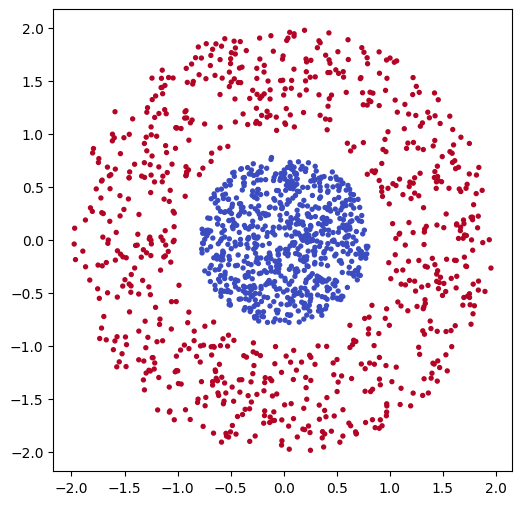

(array([[ 1.23477806,  0.58571107],
        [-0.9252213 , -1.60099232],
        [ 0.50828517,  0.25176821],
        ...,
        [ 1.05111352,  1.31793821],
        [ 0.96832565, -1.65761837],
        [ 0.25511693, -0.52091945]], shape=(1050, 2)),
 array([[ 3.44591051e-01,  4.99560288e-01],
        [ 9.95245418e-01,  3.39736107e-01],
        [ 1.38827310e+00, -8.35351568e-01],
        [ 1.97735465e-01,  3.82186750e-02],
        [ 7.57791047e-02,  5.56356996e-01],
        [ 8.62377047e-01, -1.76932933e+00],
        [-1.85100410e-01,  1.58232140e+00],
        [-5.25995317e-01,  8.81673745e-01],
        [-2.11070834e-01,  6.88419694e-01],
        [ 3.38111812e-01, -6.14317124e-02],
        [-8.42949431e-01, -8.59989681e-01],
        [ 1.72243311e+00,  4.13485427e-02],
        [ 6.24703122e-01, -1.01357590e+00],
        [ 1.23143191e-01, -2.72961878e-01],
        [ 1.62580157e+00, -4.52466124e-01],
        [-3.23931392e-02, -8.56220576e-02],
        [-1.72243350e+00,  3.95304489e-01],
    

In [53]:
sol = Solution1()
sol.create_dataset()
sol.draw_dataset()
sol.split_dataset()

Full report for model A


Model name: A
Parameters amount: 15
Test accuracy: 0.8133333288298713
Model train time: 42.544302058000085




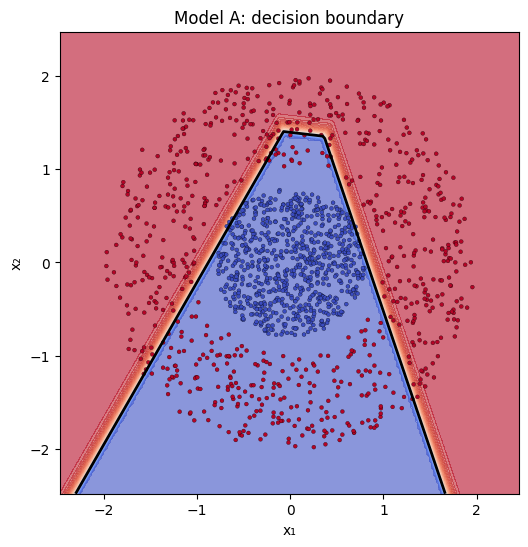

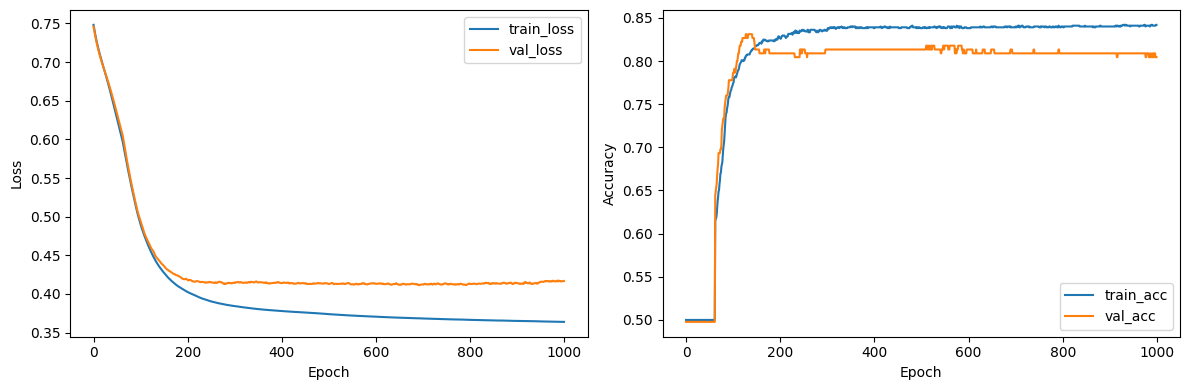

In [54]:
sol.full_model_stats("A")

Full report for model B


Model name: B
Parameters amount: 609
Test accuracy: 0.9999999743037754
Model train time: 39.682909698




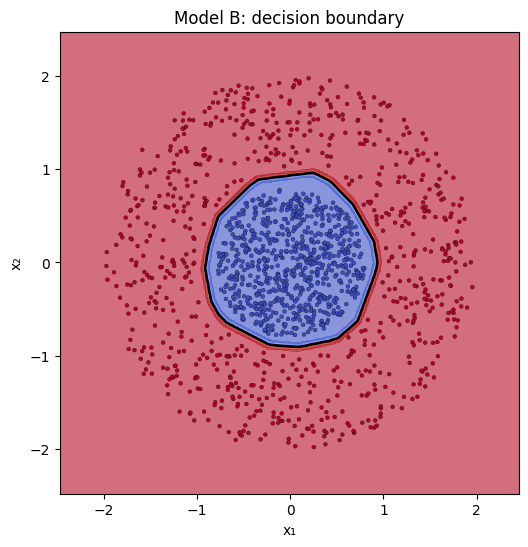

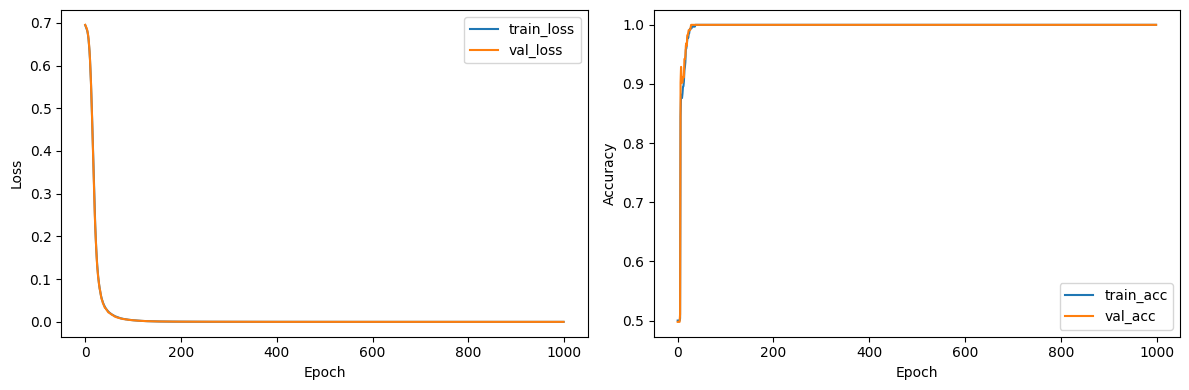

In [55]:
sol.full_model_stats("B")

Full report for model C


Model name: C
Parameters amount: 15
Test accuracy: 0.8266666629579332
Model train time: 37.601555706




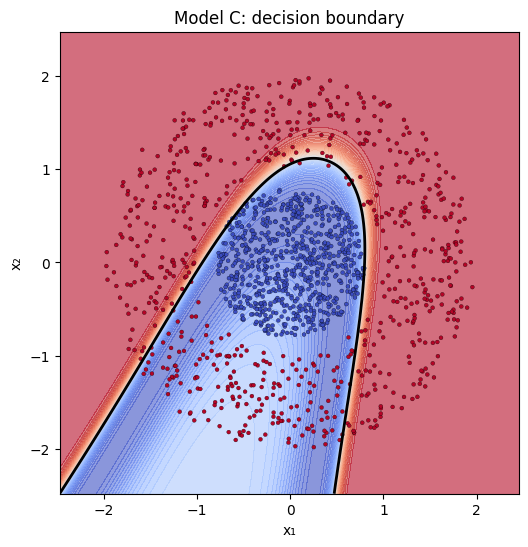

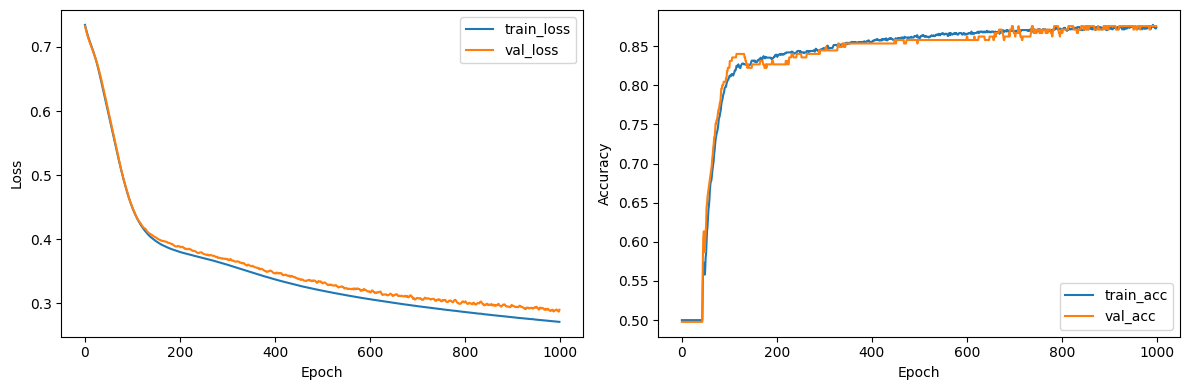

In [56]:
sol.full_model_stats("C")

### Часть 2 ###

In [57]:
emds = {}
for name in ("A", "B", "C"):
  emb = sol.get_embeddings(name)
  emds[name] = emb

In [58]:
reducer = TSNE(n_components=2)
emds["B"] = reducer.fit_transform(emds["B"])

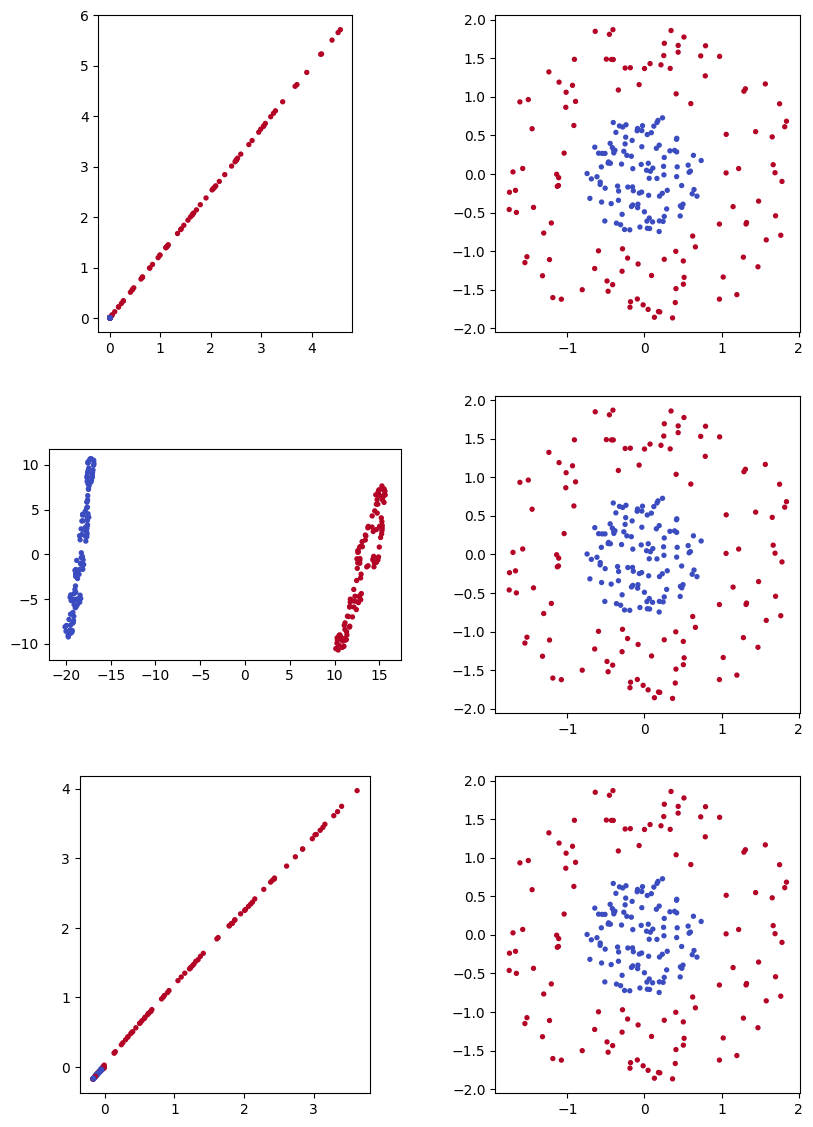

In [59]:
figure, axes = plt.subplots(3, 2, figsize=(10, 14))

for i, (name, emb) in enumerate(emds.items()):
    axes[i, 0].scatter(emb[:, 0], emb[:, 1], c=sol.y_test, cmap='coolwarm', s=8)
    axes[i, 0].set_aspect('equal')

    axes[i, 1].scatter(sol.X_test[:, 0], sol.X_test[:, 1], c=sol.y_test, cmap='coolwarm', s=8)
    axes[i, 1].set_aspect('equal')

plt.show()

Вывод. В исходном пространстве классы линейно неразделимы: класс 0 — круг в центре, класс 1 — кольцо вокруг него, и никакая прямая их не разделит. Последний слой сети — линейный, он может провести только прямую . Поэтому задача скрытых слоёв — нелинейно преобразовать пространство так, чтобы на предпоследнем слое классы стали линейно разделимыми. Эмбеддинги показывают, насколько это удалось каждой модели.

Модель B ([16, 16, 16], ReLU) справилась лучше всех: её эмбеддинги образуют два непересекающихся кластера, по одному на класс, и их легко разделить гиперплоскостью.

Модель C ([2, 2], GELU, test accuracy 0.85) отобразила точки почти на одну прямую: оба нейрона выучили практически один и тот же признак. Большая часть точек класса 1 уходит вдоль прямой далеко от класса 0, но часть кольца попадает в ту же область, что и класс 0. В исходном пространстве это видно по границе решения: она гладкая, но не замкнута и уходит «хвостом» на бесконечность, захватывая нижнюю часть кольца.

Модель A ([2, 2], ReLU, test accuracy 0.83) ведёт себя похоже, но хуже: из-за ReLU все эмбеддинги неотрицательны, и часть точек обоих классов схлопывается около (0, 0), в зону, где нейроны выдают ноль. Граница решения кусочно-линейная и тоже не замкнута.

Итог: сеть распутывает классы, перестраивая пространство признаков так, что нелинейная граница (окружность) становится линейной в пространстве эмбеддингов. Для этого сети нужна достаточная ширина: если в скрытых слоях нейронов не больше, чем размерность входа (у A и C по 2 при двумерном входе), область решения всегда неограничена. Такая сеть в принципе не может обвести круг, и полностью распутать классы ей не удаётся. Широкая модель B этого ограничения лишена. При одинаковой малой ширине активация влияет на качество: гладкая GELU (C) даёт более плавную границу и не теряет информацию в мёртвой зоне, поэтому немного точнее ReLU (A), но фундаментальное ограничение ширины не снимает.

### Часть 3 ###

In [63]:
sigmas = [0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]

result = []
for name in ("A", "B", "C"):
  rng = np.random.default_rng(21)
  s_accs = {}
  for s in sigmas:
    noise = rng.normal(loc=0, scale=s, size=sol.X_test.shape)
    noisy_test = sol.X_test + noise

    _, acc = sol.eval_model(name, noisy_test, sol.y_test)

    s_accs[s] = acc
  result.append(s_accs)

In [64]:
import pandas as pd
df_noise = pd.DataFrame(result, columns=sigmas, index=["A", "B", "C"])
df_noise = df_noise.T

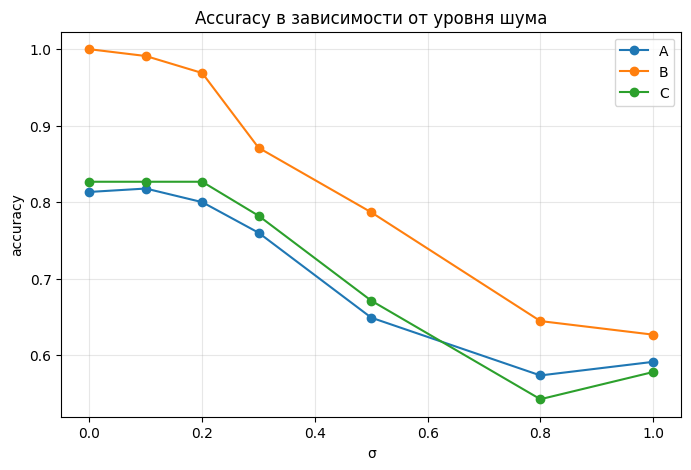

In [65]:
plt.figure(figsize=(8, 5))
for name in ("A", "B", "C"):
    plt.plot(df_noise.index, df_noise[name], marker='o', label=name)
plt.xlabel("σ")
plt.ylabel("accuracy")
plt.title("Accuracy в зависимости от уровня шума")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [67]:
outliers_fractions = [0.0, 0.01, 0.1, 0.15, 0.2, 0.3, 0.5]

result_outliers = []
for f in outliers_fractions:
  data = {}
  for name in ("A", "B", "C"):
    sol = Solution1(outliers_fraction=f, use_outliers=True)
    sol.create_dataset()
    sol.split_dataset()
    sol.build_model(name)
    sol.train_model(name, sol.X_train, sol.y_train)
    _, acc = sol.eval_model(name, sol.X_test, sol.y_test)
    data[name] = acc
  result_outliers.append(data)

In [68]:
df_outliers = pd.DataFrame(result_outliers, columns=("A", "B", "C"), index=outliers_fractions)

In [41]:
df_outliers

,A,B,C
0.00,0.675556,1.0,0.791111
0.01,0.497778,1.0,0.773333
0.10,0.502222,1.0,0.826667
0.15,0.573333,1.0,0.977778
0.20,0.502222,1.0,0.782222
0.30,0.724444,1.0,0.800000
0.50,0.822222,1.0,0.964444


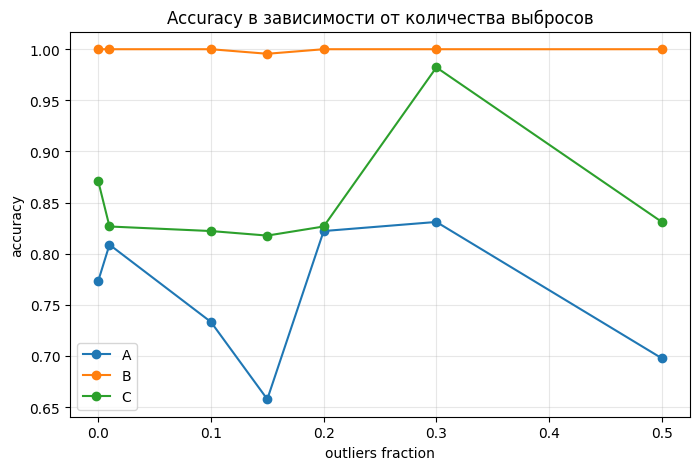

In [69]:
plt.figure(figsize=(8, 5))
for name in ("A", "B", "C"):
    plt.plot(df_outliers.index, df_outliers[name], marker='o', label=name)
plt.xlabel("outliers fraction")
plt.ylabel("accuracy")
plt.title("Accuracy в зависимости от количества выбросов")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [77]:
widths = [16, 8, 4, 3, 2, 1]

set_seed()
sol = Solution1()
sol.create_dataset()
sol.split_dataset()

(array([[ 0.64031788, -1.30632847],
        [ 1.52924905, -1.08282996],
        [ 0.33073405,  0.04700536],
        ...,
        [-0.22017999,  1.12789696],
        [-0.45015811,  1.54797643],
        [ 0.3648497 ,  0.13678394]], shape=(1050, 2)),
 array([[ 3.28107511e-02, -4.72767451e-01],
        [ 1.22349505e+00,  9.18817988e-01],
        [ 8.52258690e-01, -9.96085155e-01],
        [-4.05400175e-01,  3.41609484e-01],
        [-5.93102200e-01, -3.35693708e-01],
        [-1.64551453e+00, -1.81105082e-01],
        [ 3.57045650e-01,  1.81397245e+00],
        [ 1.12329894e+00, -2.83702040e-01],
        [ 6.10218709e-02, -5.66782870e-02],
        [ 5.54166936e-01, -1.95135956e-01],
        [ 9.90917062e-01, -2.14658418e-01],
        [ 1.77088736e+00,  1.29457753e-04],
        [-1.21552253e+00,  1.15454232e+00],
        [ 3.06032673e-01,  5.96802067e-02],
        [-5.38778220e-01, -1.84889238e+00],
        [ 4.76360605e-01,  3.77225477e-01],
        [ 1.26672574e+00,  8.65519462e-01],
    

In [79]:
width_result = []
for w in widths:
  name = f"W_{w}"
  sol.models[name] = MLP(**{"hidden_sizes": [w] * 3, "activation": nn.ReLU()})
  sol.train_model(name, sol.X_train, sol.y_train)
  _, acc = sol.eval_model(name, sol.X_test, sol.y_test)
  width_result.append({"name": name, "accuracy": acc})

In [80]:
width_result

[{'name': 'W_16', 'accuracy': 0.9999999743037754},
 {'name': 'W_8', 'accuracy': 0.9999999743037754},
 {'name': 'W_4', 'accuracy': 0.9999999743037754},
 {'name': 'W_3', 'accuracy': 0.9022222195731269},
 {'name': 'W_2', 'accuracy': 0.8444444391462538},
 {'name': 'W_1', 'accuracy': 0.5022222100363838}]

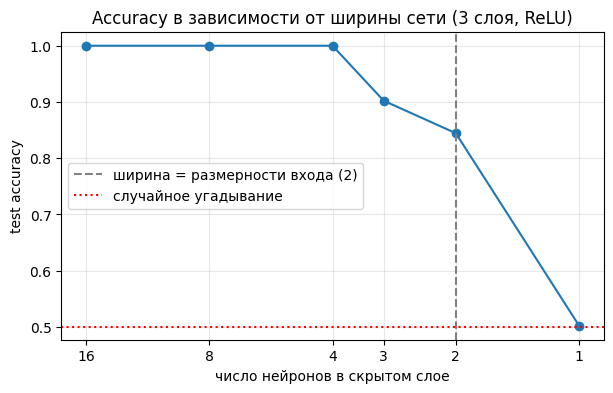

In [87]:
df_w = pd.DataFrame(width_result)
df_w["width"] = df_w["name"].str.replace("W_", "").astype(int)

plt.figure(figsize=(7, 4))
plt.plot(df_w["width"], df_w["accuracy"], marker="o")
plt.axvline(2, color="gray", linestyle="--", label="ширина = размерности входа (2)")
plt.axhline(0.5, color="red", linestyle=":", label="случайное угадывание")
plt.xscale("log", base=2)
plt.xticks(df_w["width"], df_w["width"])
plt.gca().invert_xaxis()
plt.xlabel("число нейронов в скрытом слое")
plt.ylabel("test accuracy")
plt.title("Accuracy в зависимости от ширины сети (3 слоя, ReLU)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Вывод мини-исследования. Сильнее всего на результат влияет уменьшение числа нейронов: при сокращении ширины с 16 до 1 точность модели падает со 100% до 50%, то есть до случайного угадывания. Падение носит пороговый характер: до ширины 4 включительно качество не меняется, при ширине 3 и 2 начинаются ошибки (90% и 84%), при ширине 1 модель не обучается. Это согласуется с теорией: при ширине скрытых слоёв не больше размерности входа (2) сеть не может построить замкнутую границу вокруг класса 0.

На втором месте шум входа: точность модели B снижается плавно, со 100% до примерно 63% при σ = 1. До σ ≈ 0.2 модель почти устойчива, а затем точность быстро падает. Порог совпадает с шириной зазора между классами (0.2): пока шум меньше зазора, точки редко оказываются на «чужой» стороне границы. Важно, что шум, в отличие от ширины, ухудшает сами данные: при большом σ классы перекрываются, и никакая модель не сможет классифицировать их без ошибок.

Выбросы, расположенные далеко от классов, на широкую модель B практически не влияют: точность остаётся около 100% даже при доле выбросов 0.5. Выбросы лежат вне области данных и не мешают сети провести правильную границу вокруг круга. Для узких моделей A и C результаты колеблются в пределах 0.66–0.98 без монотонной зависимости от доли выбросов. Это объясняется нестабильностью обучения узких сетей (результат сильно зависит от инициализации), а не влиянием выбросов.

Итог: ширина сети > шум входа >> выбросы. Недостаточная ёмкость модели — фундаментальное ограничение, которое не компенсируется ничем, а далёкие выбросы достаточно широкая сеть просто игнорирует.